In [ ]:
import numpy as np; import pandas as pd; import matplotlib.pyplot as plt; import shutil; import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
shutil.unpack_archive('BasketProducts.zip','data')

#1

##1.1. Загрузка и предобработка данных:
Загрузите данные и очистите их (удалите дубликаты, обработайте
пропуски и т.д.).


In [ ]:
data = pd.read_csv('data/BasketProducts.csv',index_col='index')

display(data.duplicated().sum())
data = data.drop_duplicates()

display(data.isnull().sum())
data['product'] = data['product'].fillna(data['product'].mode())
data['brand'  ] = data['brand'  ].fillna(data['brand'  ].mode())
data['rating' ] = data['rating' ].fillna(data['rating' ].mean())

np.int64(354)

,0
product,1
category,0
sub_category,0
brand,1
sale_price,0
market_price,0
type,0
rating,8463
description,113


##1.2. Анализ данных:
Проанализируйте данные, чтобы понять, какие товары наиболее
популярны (например, по количеству покупок или по частоте взаимодействия).


In [ ]:
display(data.shape)
display(data.info())
display(data.describe())
display(data.head())

(27555, 10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27555 entries, 0 to 27554
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   index         27555 non-null  int64  
 1   product       27554 non-null  object 
 2   category      27555 non-null  object 
 3   sub_category  27555 non-null  object 
 4   brand         27554 non-null  object 
 5   sale_price    27555 non-null  float64
 6   market_price  27555 non-null  float64
 7   type          27555 non-null  object 
 8   rating        27555 non-null  float64
 9   description   27440 non-null  object 
dtypes: float64(3), int64(1), object(6)
memory usage: 2.1+ MB


None

,index,sale_price,market_price,rating
count,27555.00000,27555.000000,27555.000000,27555.00000
mean,13778.00000,322.514808,382.056664,3.94341
std,7954.58767,486.263116,581.730717,0.61255
min,1.00000,2.450000,3.000000,1.00000
25%,6889.50000,95.000000,100.000000,3.94341
50%,13778.00000,190.000000,220.000000,3.94341
75%,20666.50000,359.000000,425.000000,4.20000
max,27555.00000,12500.000000,12500.000000,5.00000


,index,product,category,sub_category,brand,sale_price,market_price,type,rating,description
0,1,Garlic Oil - Vegetarian Capsule 500 mg,Beauty & Hygiene,Hair Care,Sri Sri Ayurveda,220.0,220.0,Hair Oil & Serum,4.1,This Product contains Garlic Oil that is known...
1,2,Water Bottle - Orange,"Kitchen, Garden & Pets",Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,"Each product is microwave safe (without lid), ..."
2,3,"Brass Angle Deep - Plain, No.2",Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,"A perfect gift for all occasions, be it your m..."
3,4,Cereal Flip Lid Container/Storage Jar - Assort...,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,"Laundry, Storage Baskets",3.7,Multipurpose container with an attractive desi...
4,5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Nivea Creme Soft Soap gives your skin the best...


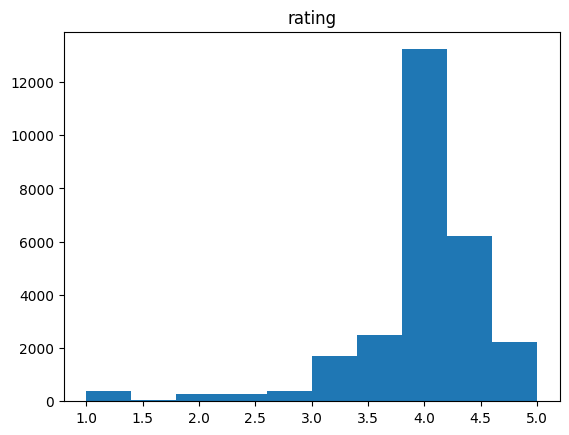




Выведем топ 5 по рейтингу по всем товарам вообще:


,product,category,sub_category,brand,sale_price,market_price,type,rating,description,discount
index,,,,,,,,,,
9579,Flushable Toilet Wipes - Imported,Cleaning & Household,All Purpose Cleaners,Pure Wipes,229.00,229.0,Imported Cleaners,5.0,Pure Flushable Toilet Wipes can be used as a c...,0.000000
7282,Premium Digital Tampon - Heavy Flow,Beauty & Hygiene,Feminine Hygiene,Sirona,227.01,329.0,Tampons & Menstrual Cups,5.0,Sirona’s Premium Digital Tampons are designed ...,44.927536
13011,Deep Brightening & Whitening Beauty Facial Mask,Beauty & Hygiene,Skin Care,Mondsub,310.00,1000.0,Face Care,5.0,MONDSUB Deep Brightening & Whitening Beauty Fa...,222.580645
14479,Hevibase Induction Compatible Pressure Cooker...,"Kitchen, Garden & Pets",Cookware & Non Stick,Hawkins,1949.00,2050.0,Pressure Cookers,5.0,The Hawkins Hevibase Pressure Cooker is made o...,5.182145
7905,Lemon Essentail Oil - 100% Pure & Natural,Beauty & Hygiene,Skin Care,Aroma Treasures,185.25,195.0,Aromatherapy,5.0,"Lemon oil has a high vitamin content, which ma...",5.263158


,count
category,
Beauty & Hygiene,7683
Gourmet & World Food,4677
"Kitchen, Garden & Pets",3457
Snacks & Branded Foods,2810
"Foodgrains, Oil & Masala",2673
Cleaning & Household,2650
Beverages,884
"Bakery, Cakes & Dairy",850
Baby Care,610


,count
brand,
Fresho,638
bb Royal,539
BB Home,428
DP,243
Fresho Signature,170
bb Combo,167
Amul,153
INATUR,142
Himalaya,141


,discount
count,27201.000000
mean,17.885661
std,28.612038
min,0.000000
25%,0.000000
50%,5.263158
75%,25.000000
max,512.244898


In [ ]:
plt.hist(data['rating']);plt.title('rating');plt.show();print(f'\n\n')

data=data.sort_values(by='rating',ascending=False)
print(f'Выведем топ 5 по рейтингу по всем товарам вообще:')
display(data[:5])

c=data['category'].value_counts();display(c)
b=data['brand'].value_counts();display(b.head(10))
data['discount']=((data['market_price']-data['sale_price'])/data['sale_price'])*100;
display(data['discount'].describe())

#2

##2.1.
Определите, какие товары являются самыми популярными
(например, топ-10 товаров по количеству покупок). Можно использовать
функции из задания 1.2.


In [ ]:
data=data.sort_values(by='rating',ascending=False)
print(f'Выведем топ 5 по рейтингу по всем товарам вообще:')
display(data[:5])
print(f'\n\n')


data['discount'] = (data['market_price']-data['sale_price'])/data['sale_price'] * 100
display(data[['category', 'product', 'discount']])


Выведем топ 5 по рейтингу по всем товарам вообще:


,product,category,sub_category,brand,sale_price,market_price,type,rating,description,discount
index,,,,,,,,,,
9278,Body Deodorant - Ultra Sensual,Beauty & Hygiene,Fragrances & Deos,Wild Stone,159.20,199.0,Men's Deodorants,5.0,The ultimate range of irresistible masculine f...,25.000000
16005,Eggless Pancake Mix,Snacks & Branded Foods,Ready To Cook & Eat,HappyChef,99.00,249.0,Home Baking,5.0,A fluffy pancake can make your day. Make the p...,151.515152
9579,Flushable Toilet Wipes - Imported,Cleaning & Household,All Purpose Cleaners,Pure Wipes,229.00,229.0,Imported Cleaners,5.0,Pure Flushable Toilet Wipes can be used as a c...,0.000000
7282,Premium Digital Tampon - Heavy Flow,Beauty & Hygiene,Feminine Hygiene,Sirona,227.01,329.0,Tampons & Menstrual Cups,5.0,Sirona’s Premium Digital Tampons are designed ...,44.927536
20164,Supreme Scalp Rejuvenation Shampoo,Beauty & Hygiene,Hair Care,Head & shoulders,211.20,220.0,Shampoo & Conditioner,5.0,Experiencing a dry scalp? Try out the all-new ...,4.166667


,category,product,discount
index,,,
9278,Beauty & Hygiene,Body Deodorant - Ultra Sensual,25.000000
16005,Snacks & Branded Foods,Eggless Pancake Mix,151.515152
9579,Cleaning & Household,Flushable Toilet Wipes - Imported,0.000000
7282,Beauty & Hygiene,Premium Digital Tampon - Heavy Flow,44.927536
20164,Beauty & Hygiene,Supreme Scalp Rejuvenation Shampoo,4.166667
...,...,...,...
17739,Beverages,Kesar Badam Syrup,0.000000
9041,Beauty & Hygiene,Clove Pure Essential Oil,42.857143
6791,Beauty & Hygiene,Wisal EDP Oriental Perfume For Women,42.857143


##2.2.
Постройте простую рекомендательную систему, которая будет
рекомендовать эти популярные товары всем пользователям: реализуйте
функцию, которая принимает на вход ID пользователя и возвращает список
рекомендуемых товаров (например, топ- N популярных товаров).

In [ ]:
def rec_pop(c, v, n=5):
    """Returns top items by rating for a specific category/type"""
    return data[data[c] == v].sort_values('rating', ascending=False).head(n)

# Популярные товары в категории
print(rec_pop('category', 'Beauty & Hygiene', n=5))

                                   product          category  \
index                                                          
1167                     Guard 3 Cartridge  Beauty & Hygiene   
26003                         Dry Skin Gel  Beauty & Hygiene   
9278        Body Deodorant - Ultra Sensual  Beauty & Hygiene   
7282   Premium Digital Tampon - Heavy Flow  Beauty & Hygiene   
20164   Supreme Scalp Rejuvenation Shampoo  Beauty & Hygiene   

            sub_category             brand  sale_price  market_price  \
index                                                                  
1167      Men's Grooming          Gillette      171.50         175.0   
26003          Skin Care           Bio-Oil      216.00         270.0   
9278   Fragrances & Deos        Wild Stone      159.20         199.0   
7282    Feminine Hygiene            Sirona      227.01         329.0   
20164          Hair Care  Head & shoulders      211.20         220.0   

                           type  rating  \
ind

#3

In [ ]:
df=pd.read_csv('data/BasketProducts.csv',index_col='index').dropna().reset_index(drop=True);
f=['category','sub_category', 'type', 'brand']
for c in f:df[c]=df[c].apply(lambda x:str(x).lower().replace(" ",""))
df['features']=df[f].agg(' '.join,axis=1);
cv=CountVectorizer(stop_words='english')
m1=cv.fit_transform(df['features']);s1=cosine_similarity(m1).astype('float32')
m2=cv.fit_transform(df['product' ]);s2=cosine_similarity(m2).astype('float32');
fs=(s1+s2)/2
fs=pd.DataFrame(fs)
def rec_c2(t):
    i=df[df['product']==t].index[0];idx=fs[i].nlargest(11).index.tolist()
    if i in idx:idx.remove(i)
    r=df.iloc[idx].copy();r['sim']=fs.iloc[idx,i].values;return r[['product','sim']]
print(df['product'].iloc[10])
display(rec_c2(df['product'].iloc[10]))

Wheat Grass Powder - Raw


,product,sim
11040,Organic Powder - Wheat Grass,0.812500
14437,Organic Powder - Barley Grass,0.687500
14978,Wheat Grass - Powder,0.683013
772,Barley Grass Powder - Detoxifying & Alkalizing,0.661107
13965,Alfalfa Grass Powder - Detoxifying & Alkalizing,0.661107
13211,Whole Wheat Atta With Bran & Wheat Germ,0.626482
16043,Spirulina Powder,0.614277
18052,Wheat Bran,0.614277
3293,Natirel Raw Banana Flour,0.562500
9153,Pancake Mix - Whole Wheat And Chocolate,0.562500
